# JS07 Lab 2: Klasterisasi Data Non-Linear dengan DBSCAN

Jobsheet 07, Lab 2. Lab sebelumnya memakai data Iris yang bisa dipisah dengan garis lurus. Di sini pertanyaannya dibalik: bagaimana kalau sebaran datanya tidak linear?

Data sintetis dua bulan sabit dipakai untuk membuktikan bahwa K-Means gagal pada bentuk seperti ini, lalu DBSCAN menggantikannya.


## Langkah 0 - Import Library

`matplotlib` dan `seaborn` untuk plotting, `numpy` untuk operasi array.


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


## Langkah 1 - Membuat Dataset Sintetis

`make_moons` menghasilkan dua lengkungan yang saling menyilang, bentuk yang tidak mungkin dipisahkan oleh satu garis lurus.


In [2]:
from sklearn.datasets import make_moons

X, y = make_moons(200, noise=.05, random_state=0)


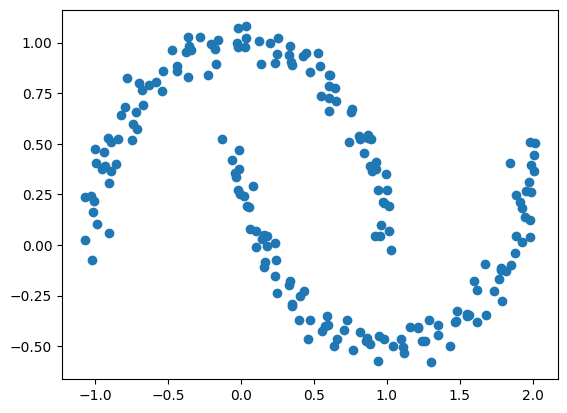

In [3]:
plt.scatter(X[:, 0], X[:, 1])
plt.show()


Terlihat dua kelompok yang melengkung satu sama lain. Jumlah cluster-nya jelas dua, tapi batas antara keduanya bukan garis lurus.


## Langkah 2 - Klasterisasi dengan K-Means

K-Means mencari centroid dan membagi ruang dengan batas linear, jadi bentuk melengkung seperti ini seharusnya jadi masalah baginya.


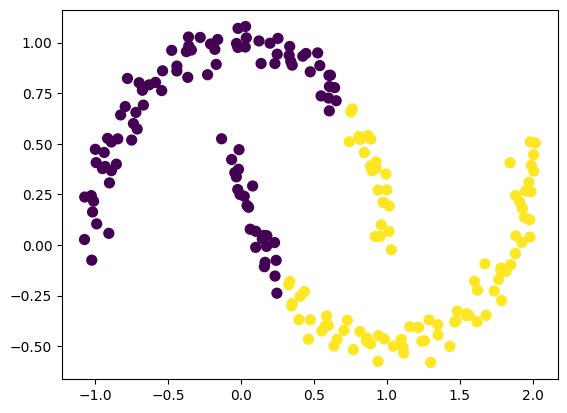

In [4]:
from sklearn.cluster import KMeans

kmeans = KMeans(2, random_state=0)
cluster = kmeans.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=cluster, s=50, cmap='viridis')
plt.show()


Hasilnya terbelah dua secara vertikal, bukan mengikuti lengkungan. Ujung bulan sabit bawah yang menjulur ke kanan malah ikut masuk ke cluster atas. Pembagiannya bisa dibayangkan sebagai satu garis imajiner yang membelah plot.


In [5]:
from sklearn.metrics import silhouette_score

print(silhouette_score(X, cluster))


0.49215648268306905


Silhouette di kisaran 0.49. Angka ini memang bukan nol, tapi cukup rendah untuk menunjukkan bahwa pemisahan clusternya tidak rapi.


## Langkah 3 - Klasterisasi dengan DBSCAN

DBSCAN tidak memakai centroid. Ia menumbuhkan cluster dari titik-titik yang berdekatan, jadi bentuk melengkung pun bisa diikuti. Dua parameternya sangat menentukan hasil: `eps` sebagai radius tetangga dan `min_samples` sebagai jumlah minimum titik di dalam radius itu.


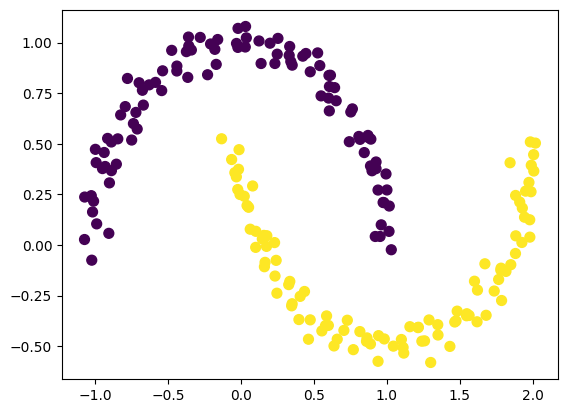

In [6]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.3, min_samples=2)
cluster_db = dbscan.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=cluster_db, s=50, cmap='viridis')
plt.show()


Sekarang kedua bulan sabit terpisah dengan bersih, termasuk ujung-ujungnya yang menjulur.


### Silhouette score untuk DBSCAN

Silhouette kembali dihitung supaya bisa dibandingkan dengan hasil K-Means.


In [7]:
from sklearn.metrics import silhouette_score

print(silhouette_score(X, cluster_db))


0.32585318950197517


Nilainya justru turun ke kisaran 0.33, lebih rendah dari K-Means, padahal secara visual DBSCAN jelas lebih benar.

Sebabnya, silhouette mengukur jarak antar titik dan mengasumsikan cluster terpisah secara linear. Pada dua lengkungan yang saling menyilang, titik tetangga di lengkungan berbeda bisa berjarak sangat dekat, sehingga skornya ikut tertekan. Metrik ini memang tidak cocok untuk bentuk seperti ini.

Alternatif evaluasinya:

1. Persentase data noise, karena DBSCAN menandai titik terpencil sebagai noise (label `-1`).
2. Inspeksi visual, yang pada kasus ini paling jujur.
3. Davies-Bouldin Index sebagai metrik kuantitatif tambahan.


### Davies-Bouldin Index

DBI mengukur separasi antar cluster, semakin kecil semakin baik, dengan rentang 0 sampai tak hingga.


In [8]:
from sklearn.metrics import davies_bouldin_score

# Compute and print Davies-Bouldin Index
db = davies_bouldin_score(X, cluster_db)

print(f"Davies-Bouldin Index: {db}")


Davies-Bouldin Index: 1.1622685374061352


### Persentase data noise

DBSCAN memberi label `-1` pada titik yang tidak masuk cluster mana pun. Porsi titik seperti ini menunjukkan seberapa longgar atau ketat parameternya.


In [9]:
noise = (cluster_db == -1).sum()
jumlah_cluster = len(set(cluster_db)) - (1 if -1 in cluster_db else 0)

print(f'Jumlah cluster: {jumlah_cluster}')
print(f'Jumlah titik noise: {noise} dari {len(cluster_db)} ({noise / len(cluster_db) * 100:.2f}%)')


Jumlah cluster: 2
Jumlah titik noise: 0 dari 200 (0.00%)


## Kesimpulan

K-Means tidak bisa mengikuti bentuk non-linear karena batas clusternya selalu linear. DBSCAN berhasil memisahkan dua bulan sabit dengan bersih.

Yang menarik, silhouette score malah lebih rendah untuk DBSCAN, jadi metrik itu tidak bisa dijadikan patokan tunggal pada data non-linear. Persentase noise, Davies-Bouldin Index, dan inspeksi visual lebih bisa dipercaya di kasus ini.
